In [1]:
''''
making sat traini`bng data
'''

"'\nmaking sat training data\n"

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt



import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os



import importlib
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [63]:
df_sats = pd.read_csv("/home/3155/satsofar")

In [7]:
df_sats

,Unnamed: 0.1,Unnamed: 0,filename,quad,streakxposition,satcrossing,row_from_nn,col_from_nn,quadrant
0,0,0.0,ztf_20221020148032_000686_zg_c03_x_0011.,4,2479,154,144,2469,4
1,1,1.0,ztf_20221020148032_000686_zg_c03_x_0011.,4,2221,1654,1644,2211,4
2,2,2.0,ztf_20221020148032_000686_zg_c03_x_0011.,4,2198,1788,1778,2188,4
3,3,3.0,ztf_20221020148032_000686_zg_c03_x_0011.,4,2238,1552,1542,2228,4
4,4,0.0,ztf_20221020138241_000686_zi_c02_x_0029.,2,203,2710,2700,193,2
...,...,...,...,...,...,...,...,...,...
67,3,NaN,ztf_20221020154120_000640_zi_c15_x_0028.,3,2840,565,555,2830,3
68,0,NaN,ztf_20221020294271_000449_zr_c16_x_0020.,4,1009,458,448,999,4
69,1,NaN,ztf_20221020294271_000449_zr_c16_x_0020.,4,1098,598,588,1088,4
70,2,NaN,ztf_20221020294271_000449_zr_c16_x_0020.,4,1476,1215,1205,1466,4


In [11]:
ranges = np.arange(-2,3)

In [12]:
ranges

array([-2, -1,  0,  1,  2])

In [64]:
#below here new
fpath_image = "/lustre/lrspec/ZTF_data/2022/1020/"
stampstosave = []
infotosave = []
# bgtosave = []
# bginfo = []

for i in range(len(df_sats)):
    addrow=0
    addcol=0
    fname = df_sats.iloc[i]["filename"]
    image_filename = fname+'fits.fz'
    # filename_start = image_filename[:40]
    image_filename_full = fpath_image + image_filename
    # print(image_filename)
    hdul = fits.open(image_filename_full)
    file1_array = hdul[df_sats.iloc[i]["quad"]].data
    row = int(df_sats.iloc[i]['satcrossing'])
    col = int(df_sats.iloc[i]['streakxposition'])
    for addcol in ranges:
#         if (row - 10  + addrow > 15) & (col  - 10 + addcol > 15):
#             # addrow=0
#             stamp = file1_array[row - 10  + addrow: row + 10 + addrow,
#                             col  - 10 + addcol : col + 10 + addcol ,
#                         ]
#             # plt.imshow(stamp)
#             # plt.show()
#             # stp, bg = ff.get_stamp_from_df(i,  cr_0820, direcname="training_aug24/implant_train/", quad=1, norm=True, addrow=addrow, addcol=addcol, iloc=True) #pretty sure this was iloc before
#             stampstosave.append(stamp)
#             infotosave.append(np.array((df_sats.iloc[i]['filename'], df_sats.iloc[i]['quad'], row, col, addcol, addrow)))
    
        for addrow in ranges:
            if (row - 10  + addrow > 15) & (col  - 10 + addcol > 15):
                # addcol=0
                stamp = file1_array[row - 10  + addrow: row + 10 + addrow,
                                col - 10 + addcol : col  + 10 + addcol ,
                            ]
                # stp, bg = ff.get_stamp_from_df(i,  cr_0820, direcname="training_aug24/implant_train/", quad=1, norm=True, addrow=addrow, addcol=addcol, iloc=True) #pretty sure this was iloc before
                stampstosave.append(stamp)
                infotosave.append(np.array(( df_sats.iloc[i]['filename'], df_sats.iloc[i]['quad'], row, col, addcol, addrow)))
    
# np.save("/lustre/lrspec/ZTF_data/training_feb26/images/cr_0820.npy", stampstosave)
# np.save("/lustre/lrspec/ZTF_data/training_feb26/info/cr_0820_info.npy", infotosave)


In [67]:
len(stampstosave)

1775

In [57]:
len(stampstosave)

710

In [43]:
np.array?

Docstring:
array(object, dtype=None, *, copy=True, order='K', subok=False, ndmin=0,
      like=None)

Create an array.

Parameters
----------
object : array_like
    An array, any object exposing the array interface, an object whose
    ``__array__`` method returns an array, or any (nested) sequence.
    If object is a scalar, a 0-dimensional array containing object is
    returned.
dtype : data-type, optional
    The desired data-type for the array. If not given, NumPy will try to use
    a default ``dtype`` that can represent the values (by applying promotion
    rules when necessary.)
copy : bool, optional
    If true (default), then the object is copied.  Otherwise, a copy will
    only be made if ``__array__`` returns a copy, if obj is a nested
    sequence, or if a copy is needed to satisfy any of the other
    requirements (``dtype``, ``order``, etc.).
order : {'K', 'A', 'C', 'F'}, optional
    Specify the memory layout of the array. If object is not an array, the
    newly crea

In [71]:
infotosave[95]

array(['ztf_20221020148032_000686_zg_c03_x_0011.', '4', '1552', '2238',
       '2', '-2'], dtype='<U40')

In [48]:
thing.shape

(14360, 20)

In [68]:
stampstosave = np.array(stampstosave)


In [69]:
infotosave = np.array(infotosave)

In [70]:
np.save("/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/images/sat_stamps.npy", stampstosave)
np.save("/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/info/sat_info.npy", infotosave)


In [5]:
loaded = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/images/sat_stamps.npy")
loaded.shape

(1775, 20, 20)

In [11]:
loaded_info = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/info/sat_stamps_info.npy")
loaded_info.shape

(1775, 6)

In [23]:
loaded_info[2][5]=='0'

True

In [27]:
loaded_info[:,5]

array(['-2', '-1', '0', ..., '0', '1', '2'], dtype='<U40')

In [29]:
np.sum((loaded_info[:,4]=='0') & (loaded_info[:,5]=='0'))

71

(71, 20, 20)

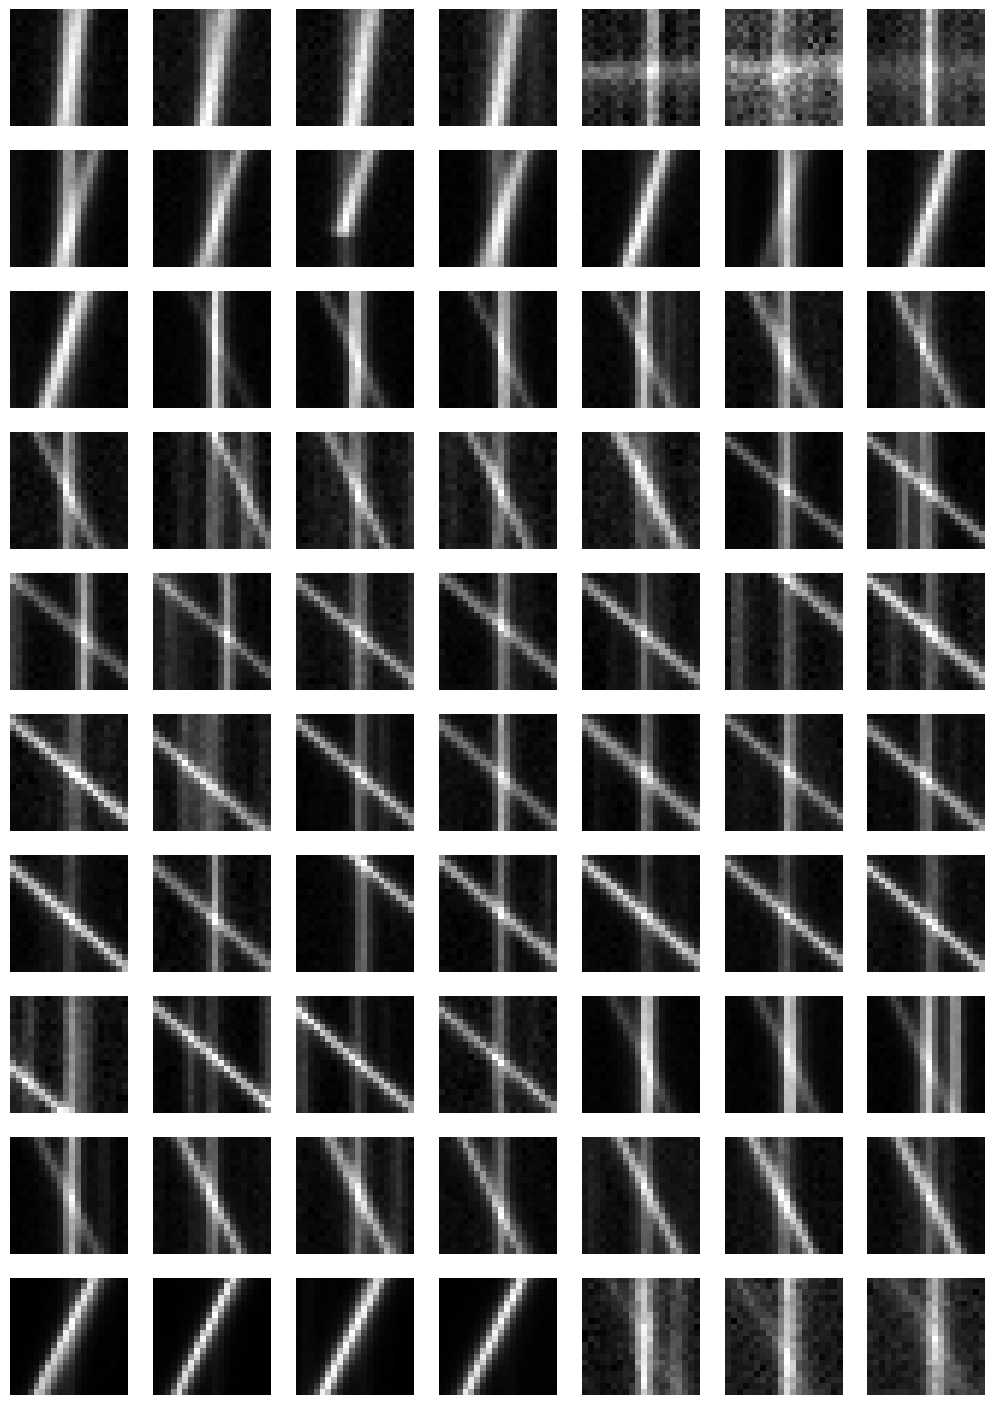

In [34]:
centered = loaded[(loaded_info[:,4]=='0') & (loaded_info[:,5]=='0')]
figcols = 7
figrows = 10
fig, ax = plt.subplots(figrows, figcols, figsize=(figcols * 1.8, figrows * 1.8))
for i in range(figrows):
    for j in range(figcols):
        index = figcols * i + j
        ax[i, j].imshow(centered[index])
        ax[i, j].set_axis_off()
        
            
# for i in range(len(loaded_info)):
#     if loaded_info[i][4]=='0' and loaded_info[i][5]=='0':
#         plt.imshow(loaded[i])
#         plt.show()